In [1]:
################### Processing csv files to get points values! ########

from datetime import datetime, timedelta
import os
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import requests
import sys
import geopandas as gpd
import pandas as pd
from shapely.geometry import MultiPoint
from shapely.geometry import Point
import fiona
import contextily as ctx
from datetime import datetime
from sklearn.ensemble import RandomForestClassifier
import simplekml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pyproj import Proj, transform
import ast
from pyproj import Transformer
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from scipy.ndimage import binary_fill_holes
from scipy.ndimage import convolve
from scipy.ndimage import distance_transform_edt
from affine import Affine

In [2]:
def count_non_nan_values(array):
        """Counts non-NaN values in an array while ignoring non-numeric elements."""
        # Filter to keep only numeric data (e.g., ints and floats)
        numeric_values = [x for x in array if isinstance(x, (int, float))] 
        # Convert to NumPy array and count non-NaN values
        return np.sum(~np.isnan(np.array(numeric_values, dtype=float)))
    
def data_prep(path, file, cutoff=0, direction=0, cutlon=0, sensor = 1):
    ####### filter the data with 015042 index ######
    df = pd.read_csv(path + file)
    df['ID'] = range(0, len(df))  # Generates IDs starting from 1
    
    if sensor == 0:
        training_data = df[['lat', 'lon', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    else:
        training_data = df[['lat', 'lon', 'SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7', 'ndmi', 'ndvi', 'savi', 'descriptio']].to_numpy()
    
    predictor = []
    target = []
    coord = []
    # Loop through each (1585, 10) array in training_data
    print('training data is:')
    #print(training_data)
    print(training_data.shape)
    #for array in training_data:
        # Get rows where the target is not 'TZ'
    mask = training_data[:, 11] != 'MZ'
    
    predictor.append(training_data[mask, 2:11])  # First 9 columns
    target.append(training_data[mask, 11])       # Target column
    coord.append(training_data[mask, :2])
    
    # Convert to NumPy arrays if desired
    predictor = np.array(predictor)
    target = np.array(target)
    coord = np.array(coord)
    
    X = predictor.reshape(-1, 9)  # Shape: (5 * 1585, 9)
    y = target.reshape(-1)        # Shape: (5 * 1585,)
    coord = coord.reshape(-1, 2)
    ### cleanse the data by removing nan ####
    valid_indices = []

    # Loop through each row and check for NaN in the first column
    for i in range(X.shape[0]):
        if not np.isnan(X[i, 0]):
            valid_indices.append(i)
    
    # Create new X and y with only valid rows
    X = X[valid_indices]
    y = y[valid_indices]
    coord = coord[valid_indices]

    print('the size of dataset is:')
    print(X.shape[0])

    if cutoff:
        if direction > 0: ### keep the eastern side
            masklon = coord[:, 1] > cutlon
        else:
            masklon = coord[:, 1] <= cutlon
    
        X = X[masklon]
        y = y[masklon]
        coord = coord[masklon]
    
        print('the size of lon filtered dataset is:')
        print(X.shape[0])
        #print(X)
    
    return X, y, coord

In [3]:
def model_train_test(X, y):
    # Initialize the RandomForestClassifier
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    
    # Fit the model to the reshaped data
    model.fit(X, y)
    
    # After training, the model can be used for predictions or evaluation
    y_pred = model.predict(X)
    
    # Calculate accuracy by comparing the predictions with the true labels (y)
    accuracy = model.score(X, y)
    
    print(f"Training and testing using the whole dataset, accuracy is: {accuracy * 100:.2f}%")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_train, y_train)
    
    # Optionally, evaluate the model on the test set
    score = model.score(X_test, y_test)
    print(f"Testing using 20% of the whole dataset, accuracy is: {score*100:.2f}%")
    
    y_pred = model.predict(X_test)

    print("the number of elements for the prediction:")
    print(y_pred.shape[0])
    cm = confusion_matrix(y_test, y_pred, labels=['VZ', 'TZ', 'WZ'])
    
    # Plot the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['VZ', 'TZ', 'WZ'])
    disp.plot(cmap='Blues', values_format='.0f')
    
    return accuracy

In [4]:
def model_across_years(X, y, X_test, y_test, coord_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X, y)
    score = model.score(X_test, y_test)
    print(f"Testing across years, accuracy is: {score*100:.2f}%")
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=['VZ', 'TZ', 'WZ'])
    
    # Plot the confusion matrix
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['VZ', 'TZ', 'WZ'])
    disp.plot(cmap='Blues', values_format='.0f')

    incorrect_indices = y_test != y_pred  # Boolean array where predictions are wrong
    misclassified_data = coord_test[incorrect_indices]  # Coordinates of misclassified samples
    misclassified_y_true = y_test[incorrect_indices]  # True values of misclassified samples
    misclassified_y_pred = y_pred[incorrect_indices]  # Predicted values of misclassified samples
    
    # Output misclassified elements
    print("\nMisclassified samples:")
    # for i in range(len(misclassified_data)):
    #     print(f"Coord: {misclassified_data[i]}, Predicted: {misclassified_y_pred[i]}, True: {misclassified_y_true[i]}")
    return misclassified_data, misclassified_y_pred, misclassified_y_true

In [5]:
def export_mispred_to_kml(coord, mispred, output_path):
    # Define colors for each class
    color_mapping = {
        'VZ': 'ff00ff00',  # Green in KML color format (aabbggrr)
        'WZ': 'ff0000ff',  # Red
        'TZ': 'ff00ffff'   # Yellow
    }
    
    # Create a KML object
    kml = simplekml.Kml()
    
    # Iterate through the coordinates and mispred values
    for (lat, lon), label in zip(coord, mispred):
        # Add a point to the KML
        pnt = kml.newpoint(coords=[(lon, lat)])
        pnt.style.iconstyle.color = color_mapping[label]
        pnt.style.iconstyle.scale = 1.0  # Icon size
        pnt.name = label  # Label as the name of the point
    
    # Save the KML file
    kml.save(output_path)
    print(f"KML file saved at: {output_path}")

In [7]:
X_1994, y_1994, coord = data_prep('/Users/bz294/Documents/WhiteZone/Points/KML/1994/', 'median.csv', 0, 0, 0, 1) ## mixing 2022 Mar and 2023 Feb
X_1994 = X_1994.astype(float)
rows_with_nan = np.any(np.isnan(X_1994), axis=1)
indices_with_nan = np.where(rows_with_nan)[0]
print("indices with nan are:")
print(indices_with_nan)

training data is:
(1573, 12)
the size of dataset is:
1442
indices with nan are:
[]


Training and testing using the whole dataset, accuracy is: 100.00%
Testing using 20% of the whole dataset, accuracy is: 72.66%
the number of elements for the prediction:
289


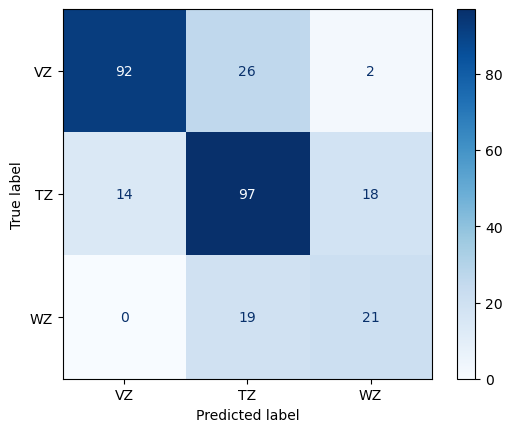

In [8]:
accuracy = model_train_test(X_1994, y_1994)

In [9]:
######### Regional Prediction ###################################
path = "/Users/bz294/Documents/WhiteZone/Points/KML/1994/"
file = "MedianCompositeValues.csv"
region_df = pd.read_csv(path + file)

In [10]:
def extract_coordinates(row):
    try:
        # Parse the JSON-like string to a dictionary
        data = ast.literal_eval(row)
        coordinates = data['coordinates']
        lon = round(coordinates[0], 10)
        lat = round(coordinates[1], 10)
        return coordinates[0], coordinates[1]  # lon, lat
    except (ValueError, KeyError):
        return None, None  # Handle parsing errors gracefully

In [11]:
############ data prep #############

region_df['lon'], region_df['lat'] = zip(*region_df['.geo'].apply(extract_coordinates))
coordinates = region_df[['lon', 'lat']].to_numpy()
feature = region_df.iloc[:, 1:12].drop(region_df.columns[[7, 10]], axis=1).to_numpy()

rows_with_nan = np.any(np.isnan(feature), axis=1)

# Get indices of rows with NaN
indices_with_nan = np.where(rows_with_nan)[0]
print("indices with nan are:")
print(indices_with_nan)

feature_cleaned = np.delete(feature, indices_with_nan, axis=0)
coordinates_cleaned = np.delete(coordinates, indices_with_nan, axis=0)

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32617", always_xy=True)

# Transform the coordinates
coord_utm = np.array([
    transformer.transform(lon, lat) for lon, lat in coordinates_cleaned
])

indices with nan are:
[]


In [12]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
    
# Fit the model to the reshaped data
model.fit(X_1994, y_1994)

# After training, the model can be used for predictions or evaluation
y_region = model.predict(feature_cleaned)

In [13]:
filename = 'output_points_1994.shp'
geometry = [Point(xy) for xy in coord_utm]

# Create a GeoDataFrame
gdf = gpd.GeoDataFrame({'y_region': y_region}, geometry=geometry)

# Set the CRS to UTM 17N (EPSG:32617)
gdf.set_crs('EPSG:32617', inplace=True)

# Save to a shapefile
output_shapefile = filename  # Define your output shapefile path
gdf.to_file(output_shapefile)

print(f'Shapefile saved to: {output_shapefile}')

Shapefile saved to: output_points_1994.shp


In [ ]:
shapefile_path = '/Users/bz294/Documents/WhiteZone/Points/Shapefiles/SEregion.shp'
gdf_polygon = gpd.read_file(shapefile_path)

In [ ]:
filename = 'output_points_2013.shp'
region_mapping = {'VZ': 1, 'WZ': 2, 'TZ': 3}
shapefile_path = filename
gdf = gpd.read_file(shapefile_path)
resolution = 30  # 30 meter resolution
minx, miny, maxx, maxy = gdf.total_bounds  # Get bounds of the shapefile
# Create a transform (affine) for the raster
transform = from_origin(minx, maxy, resolution, resolution)

# Determine raster dimensions
width = int((maxx - minx) / resolution)
height = int((maxy - miny) / resolution)

# 3. Create an empty raster to hold the points
raster = np.full((height, width), np.nan, dtype=np.float32)

# 4. Rasterize the points (using 1 for points, you can modify for other values)
for _, row in gdf.iterrows():
    point = row.geometry
    y_region_value = row['y_region'] 
    region_value = region_mapping.get(y_region_value, 0)
    # Convert point coordinates to pixel coordinates
    row_idx = int((maxy - point.y) / resolution)
    col_idx = int((point.x - minx) / resolution)
    if 0 <= row_idx < height and 0 <= col_idx < width:
        raster[row_idx, col_idx] = region_value



In [ ]:
unique_values = np.unique(raster)
unique_values

In [ ]:
# Step 1: Create a binary mask where valid pixels are 1 and NaNs are 0
valid_mask = ~np.isnan(raster)

# Step 2: Perform distance transform, where NaNs are treated as 0 (invalid area)
distance = distance_transform_edt(valid_mask)

# Step 3: Fill NaN values by assigning the nearest value from the valid pixels
# Create a copy of the raster and replace NaNs with a value based on nearest distance
raster_filled = np.copy(raster)

# Mask to fill only NaN values with the nearest valid pixel
for i in range(height):
    for j in range(width):
        if np.isnan(raster[i, j]):  # Only fill NaN pixels
            # Get the nearest valid pixel using the distance transform
            nearest_row, nearest_col = np.unravel_index(np.argmin(distance), distance.shape)
            raster_filled[i, j] = raster[nearest_row, nearest_col]  # Fill with nearest value

# You can check the unique values to confirm the filling
print(np.unique(raster_filled))

In [ ]:
output_raster_path = 'output_raster_2013.tif'

transform = from_origin(minx, maxy, resolution, resolution)

with rasterio.open(output_raster_path, 'w', driver='GTiff', height=height, width=width,
                   count=1, dtype=raster_filled.dtype, crs=gdf.crs, transform=transform) as dst:
    dst.write(raster_filled, 1)

In [ ]:
unique_values = np.unique(raster_filled)
unique_values

In [ ]:
raster_filled = np.copy(raster)
raster_filled[raster_filled == 0] = np.nan  # Mark all zero values as NaN first

raster_filled = binary_fill_holes(np.isnan(raster_filled)).astype(np.float32)

polygon_mask = geometry_mask(gdf_polygon.geometry, transform=transform, invert=True, out_shape=(height, width))
# Mask the raster using the polygon mask (only inside the polygon)
raster_filled[~polygon_mask] = np.nan  # Set outside the polygon to NaN

# Ensure there are no zeros within the polygon
raster_filled[raster_filled == 0] = np.nan  # Replace zeros inside the polygon with NaN (if any)



In [ ]:
unique_values = np.unique(raster)
unique_values

In [ ]:
target_point = np.array([550941, 2791856])

# Calculate Euclidean distances
distances = np.linalg.norm(coord_utm - target_point, axis=1)

# Find the index of the row with the minimum distance
closest_index = np.argmin(distances)

# Get the closest row and its distance
closest_row = coord_utm[closest_index]
closest_distance = distances[closest_index]

# Output results
print(f"Closest row: {closest_row}")
print(f"Index: {closest_index}")
print(f"Distance: {closest_distance}")

In [ ]:
for col in range(X_2013.shape[1]):
    col_max = X_2013[:, col].max()
    col_min = X_2013[:, col].min()
    print(f"Column {col + 1}: Max = {col_max}, Min = {col_min}")

In [ ]:
# Check for rows with all elements zero
rows_with_all_zeros = np.all(X_2013 == 0, axis=1)

# Get indices of rows with all zeros
indices_with_all_zeros = np.where(rows_with_all_zeros)[0]

# Output results
if indices_with_all_zeros.size > 0:
    print(f"Rows with all elements as zero: {indices_with_all_zeros}")
else:
    print("No rows with all elements as zero.")